In [5]:
import gzip
import yaml
import rich
import uproot
import correctionlib
import numpy as np
import mplhep as hep
import correctionlib.convert
import matplotlib.pyplot as plt
import matplotlib.text as mtext
if not hasattr(mtext.Text, "_original_init"):
    mtext.Text._original_init = mtext.Text.__init__
def _patched_text_init(self, x=0, y=0, text="", **kwargs):
    import numpy as np

    if hasattr(y, "shape") or isinstance(y, (list, tuple)):
        y = float(np.ravel(y)[0])
    if hasattr(x, "shape") or isinstance(x, (list, tuple)):
        x = float(np.ravel(x)[0])
        y += 0.01
    mtext.Text._original_init(self, x, y, text, **kwargs)
mtext.Text.__init__ = _patched_text_init
with open("../analysis/postprocess/style.yaml", "r") as f:
    style = yaml.safe_load(f)
plt.rcParams.update(style["rcParams"])

/tmp/driosper/ipykernel_2881854/1225333285.py:67: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=(10, 9), tight_layout=True)


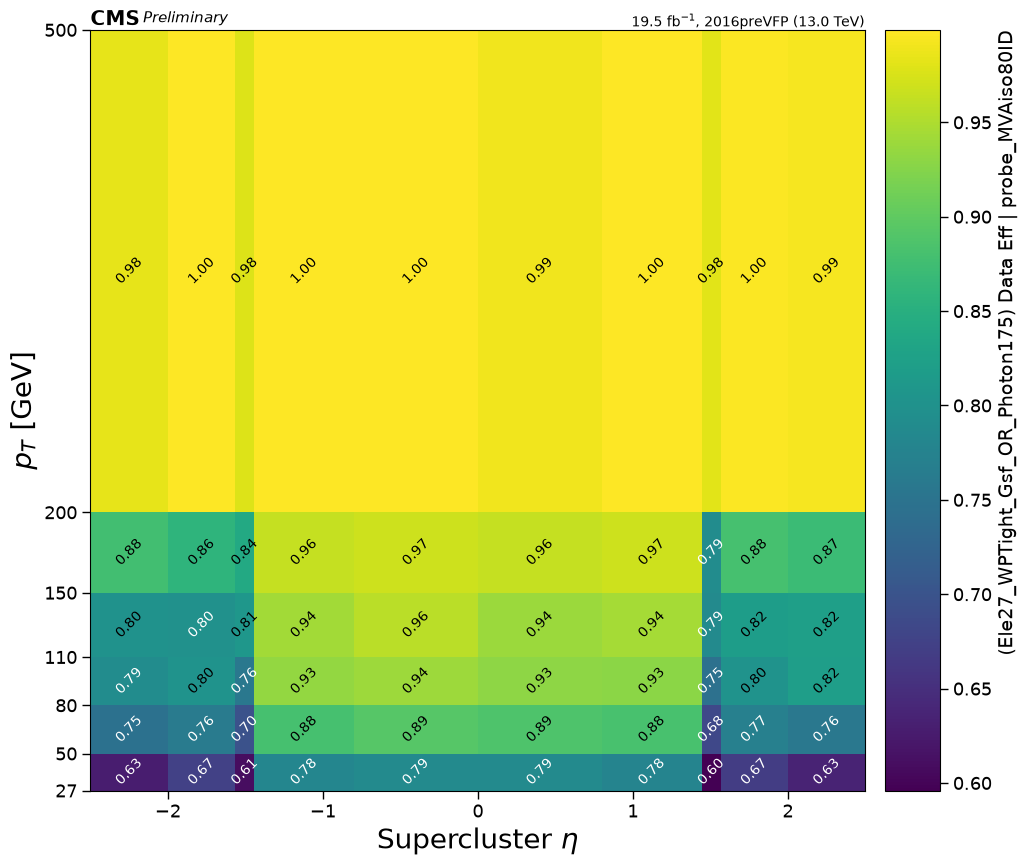

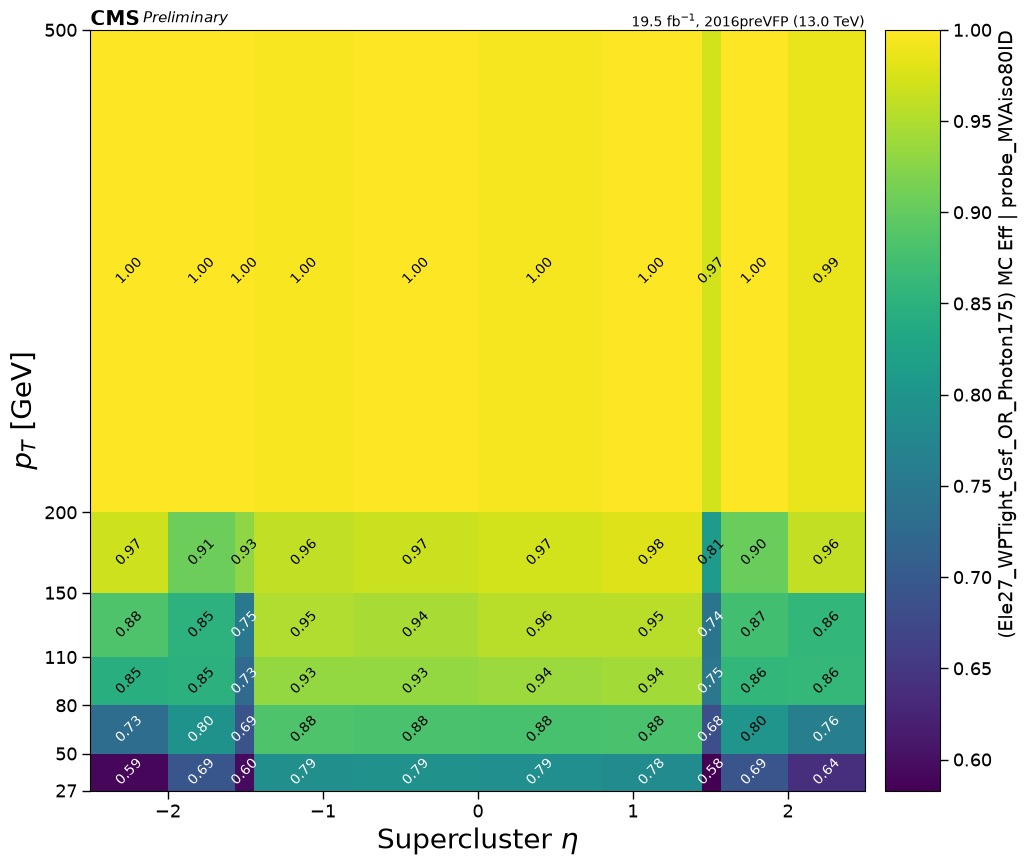

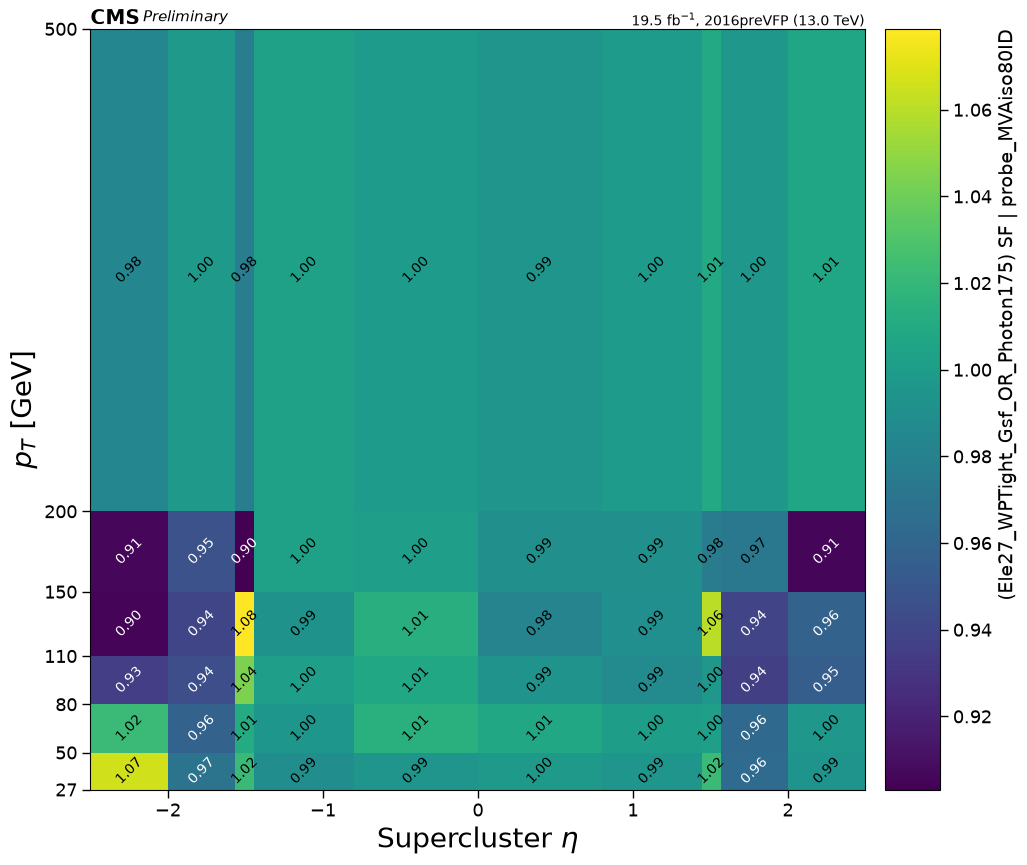

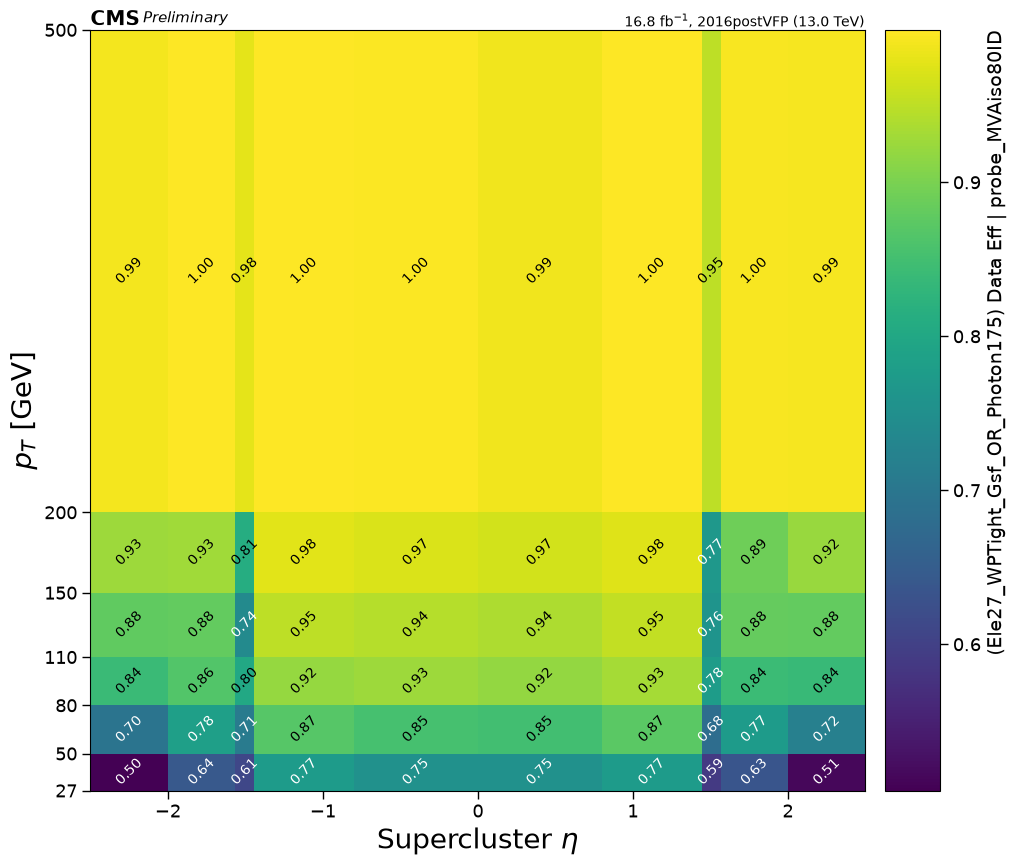

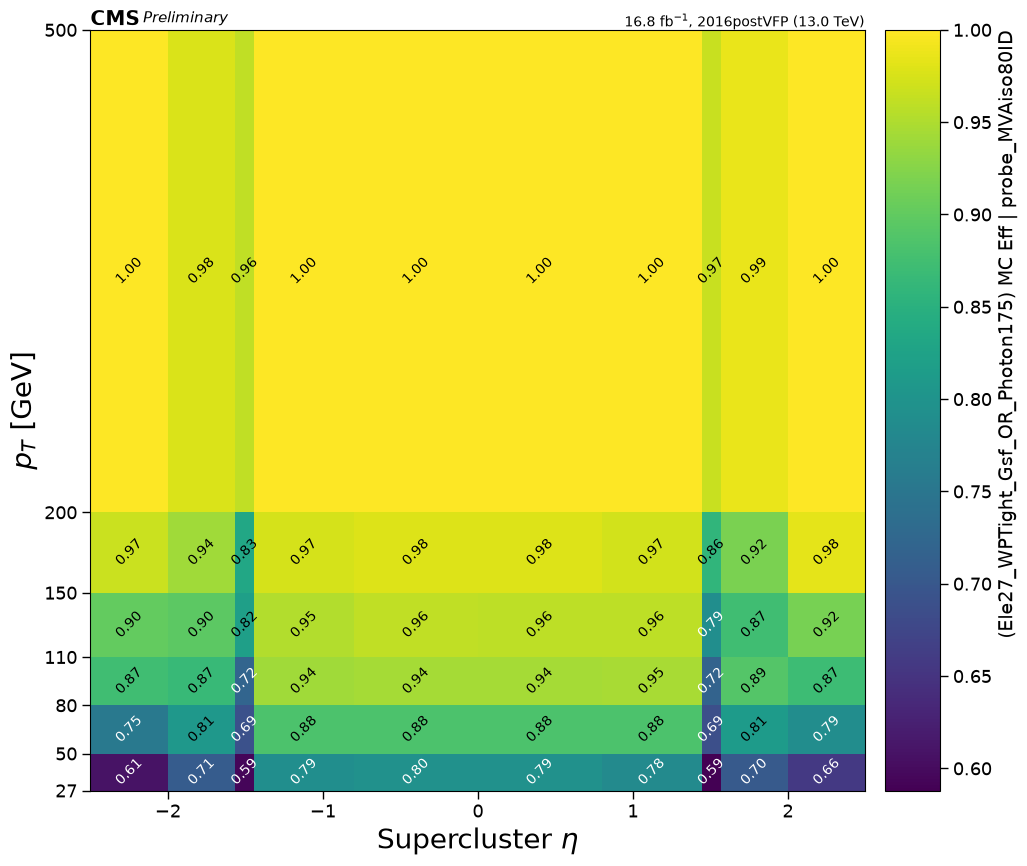

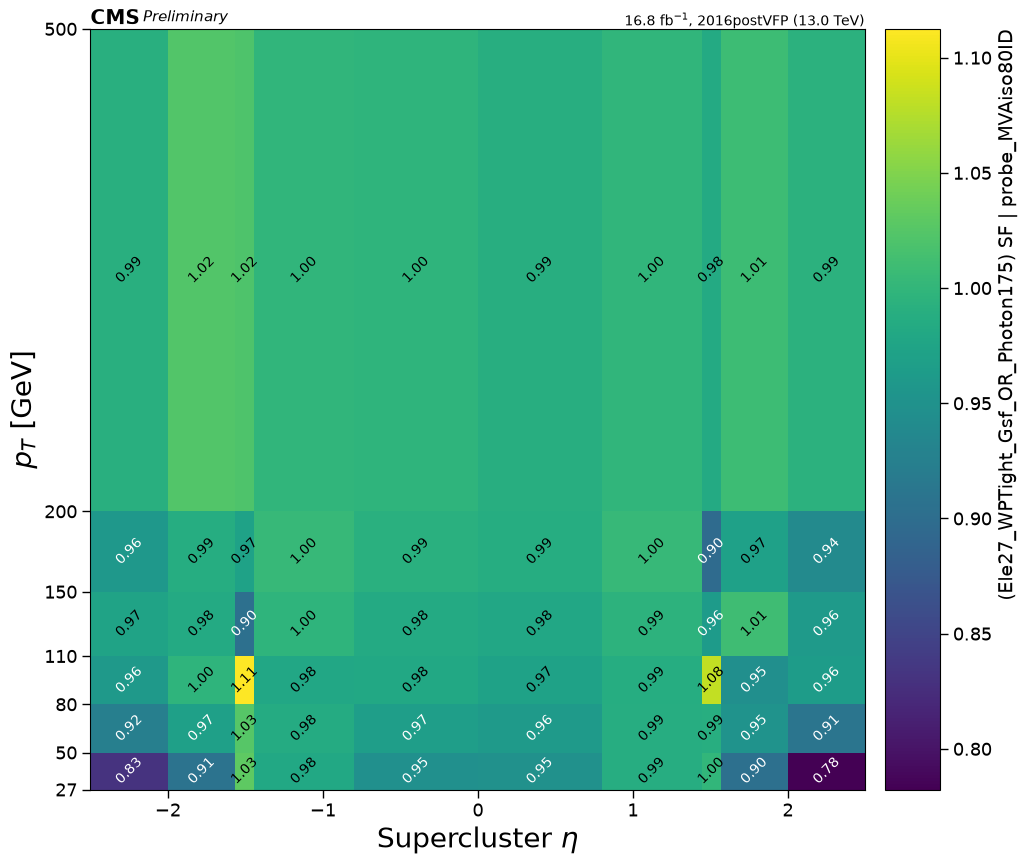

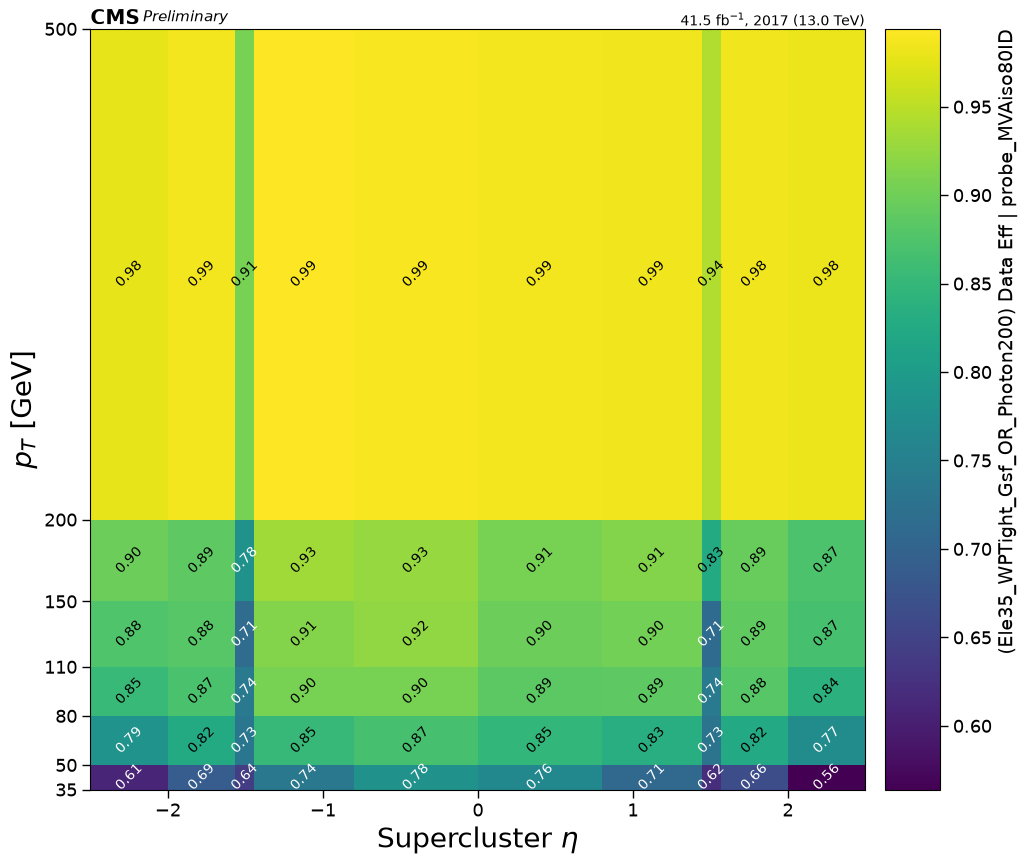

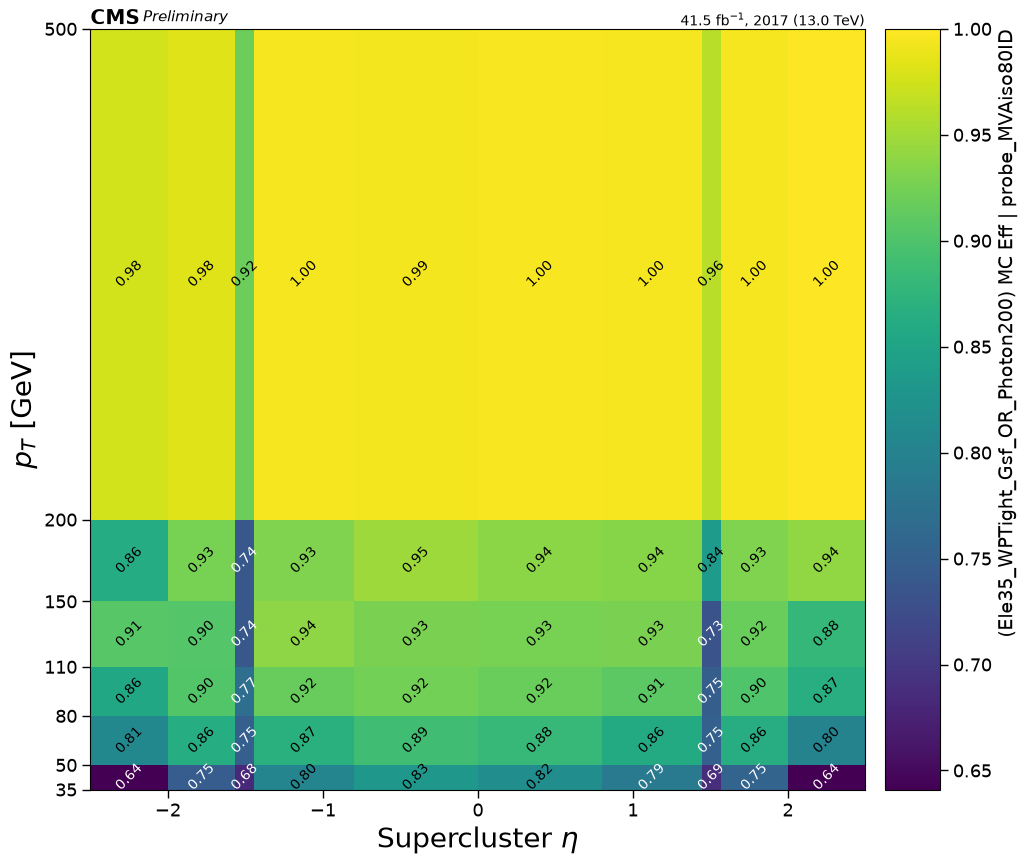

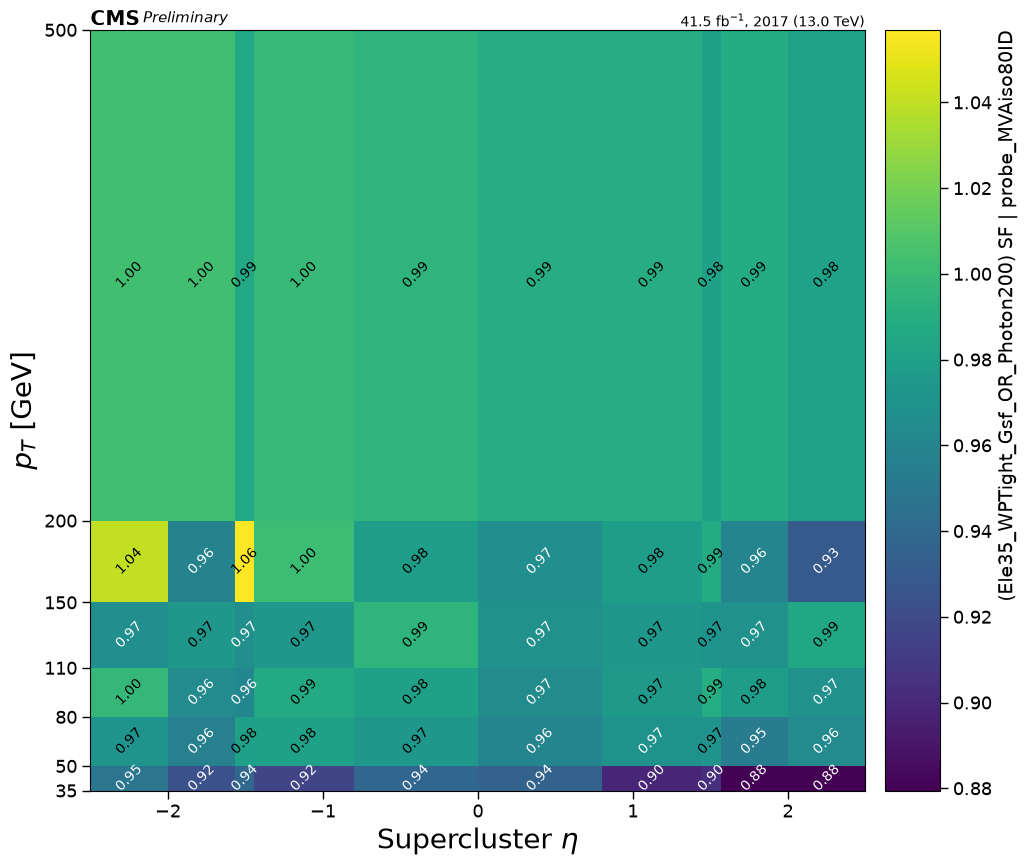

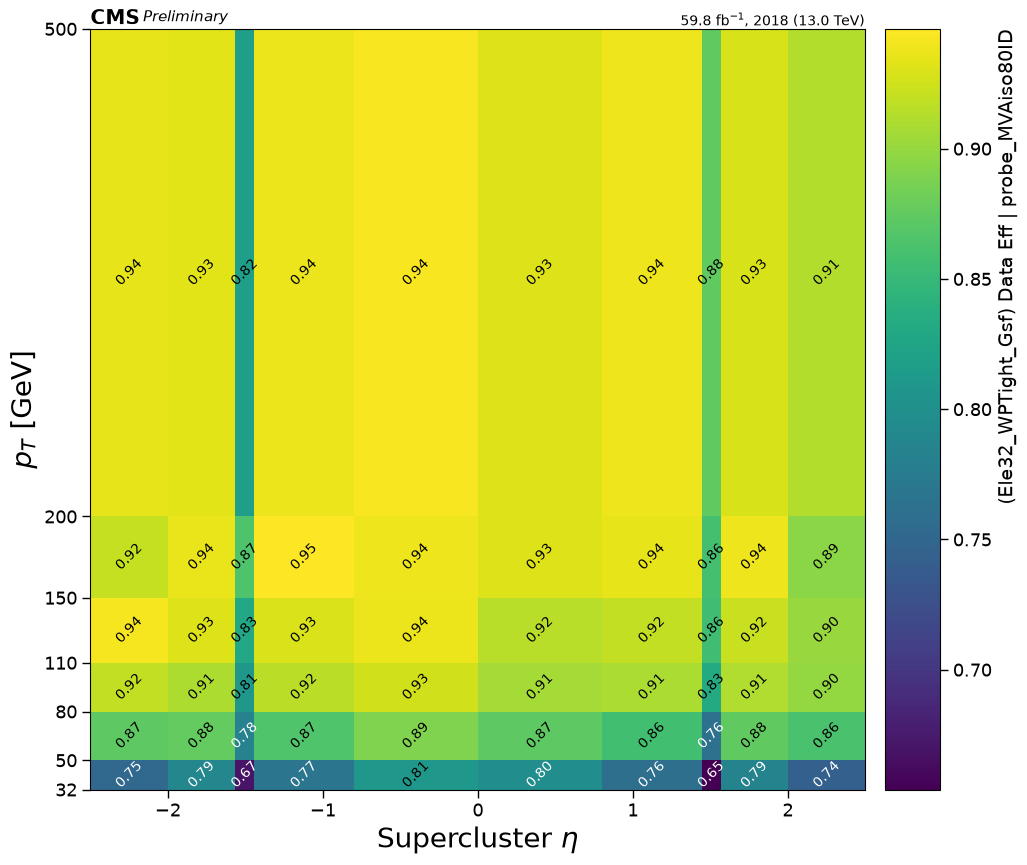

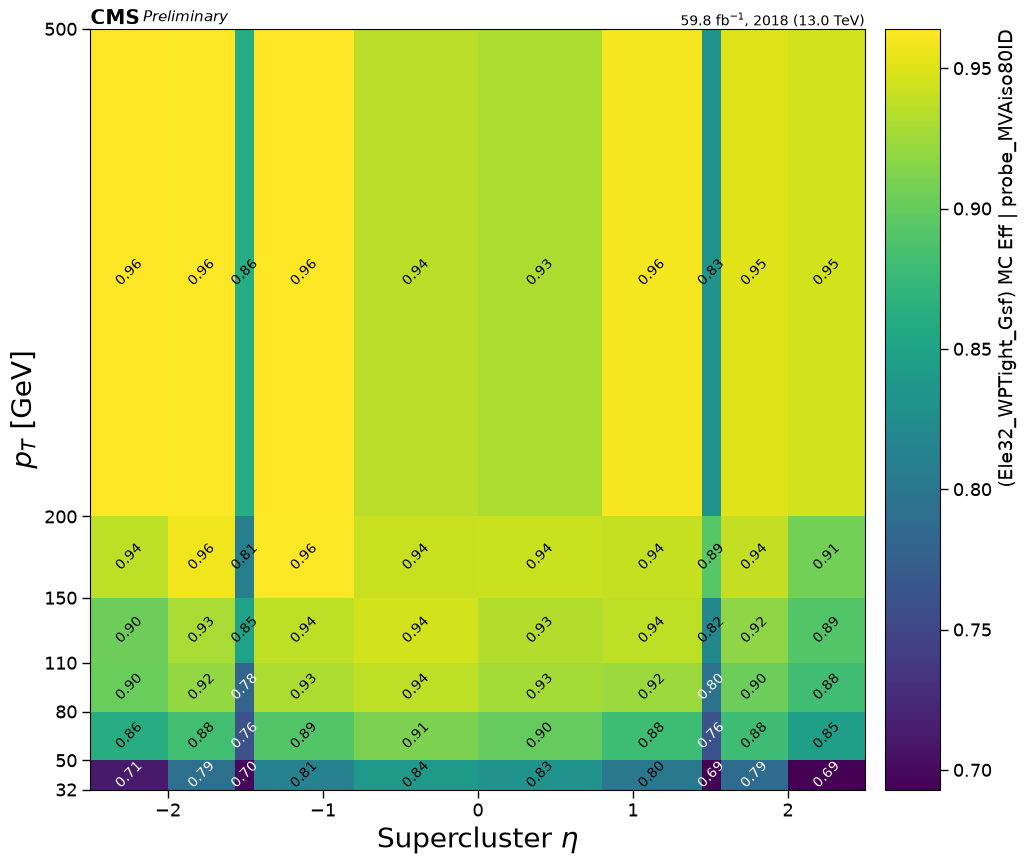

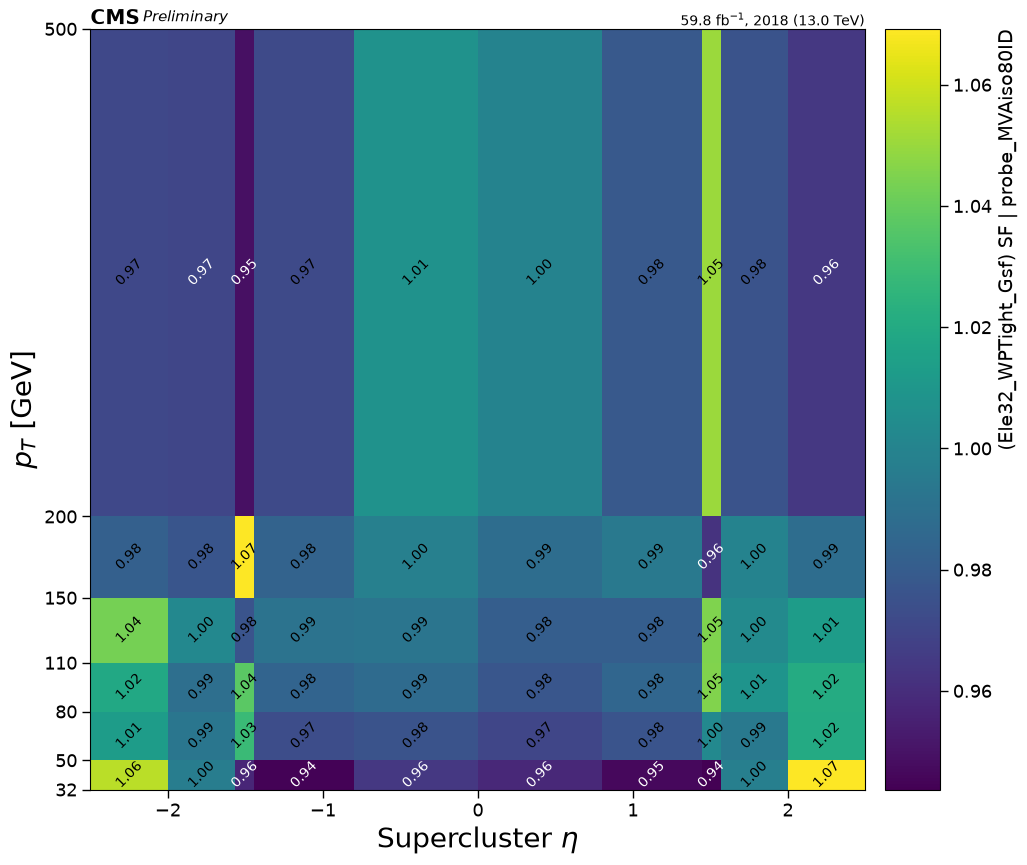

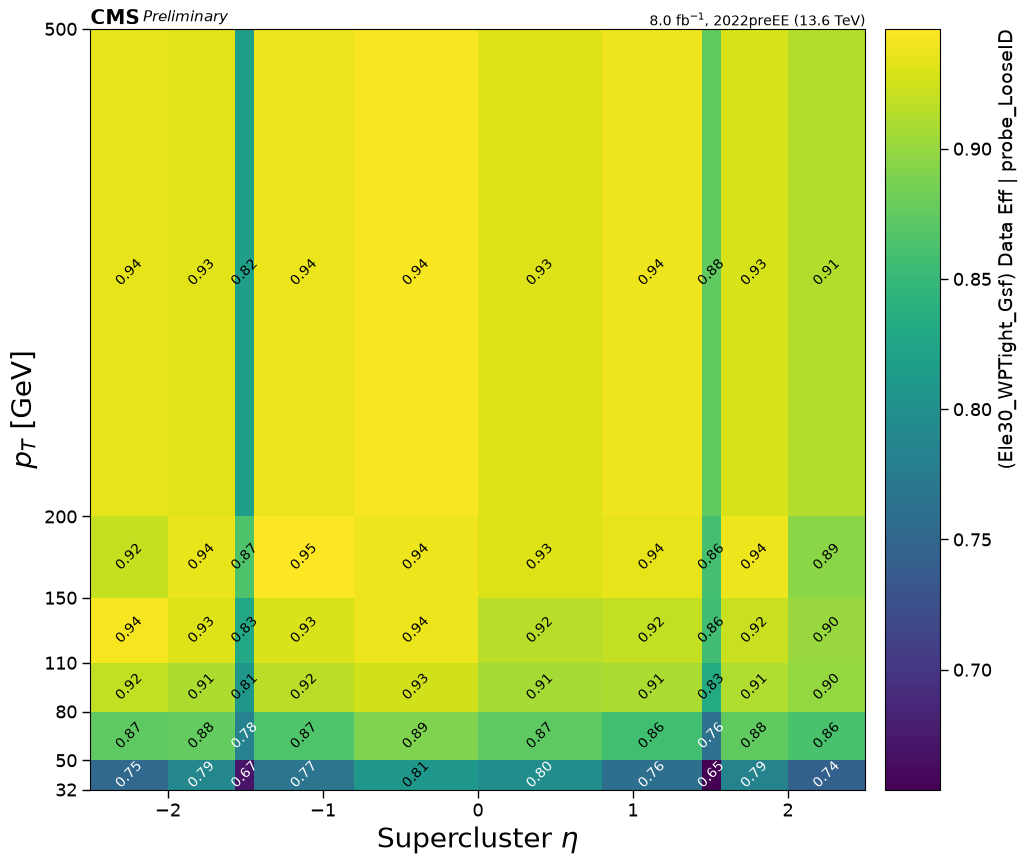

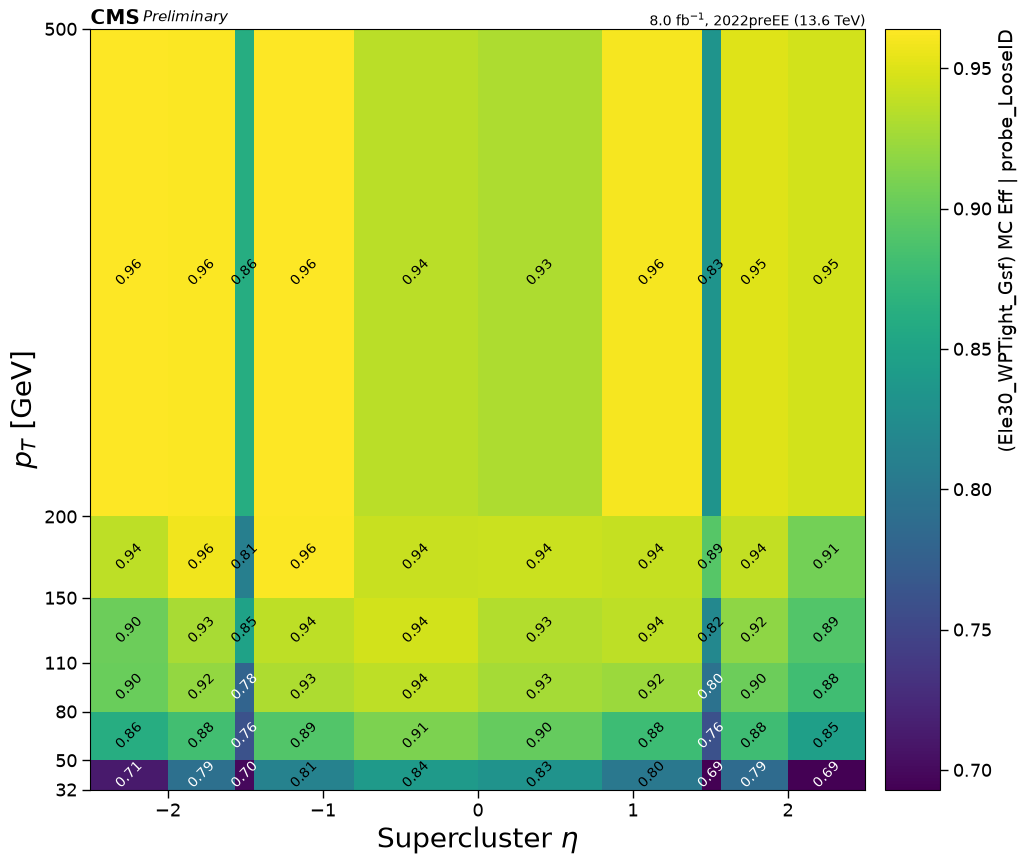

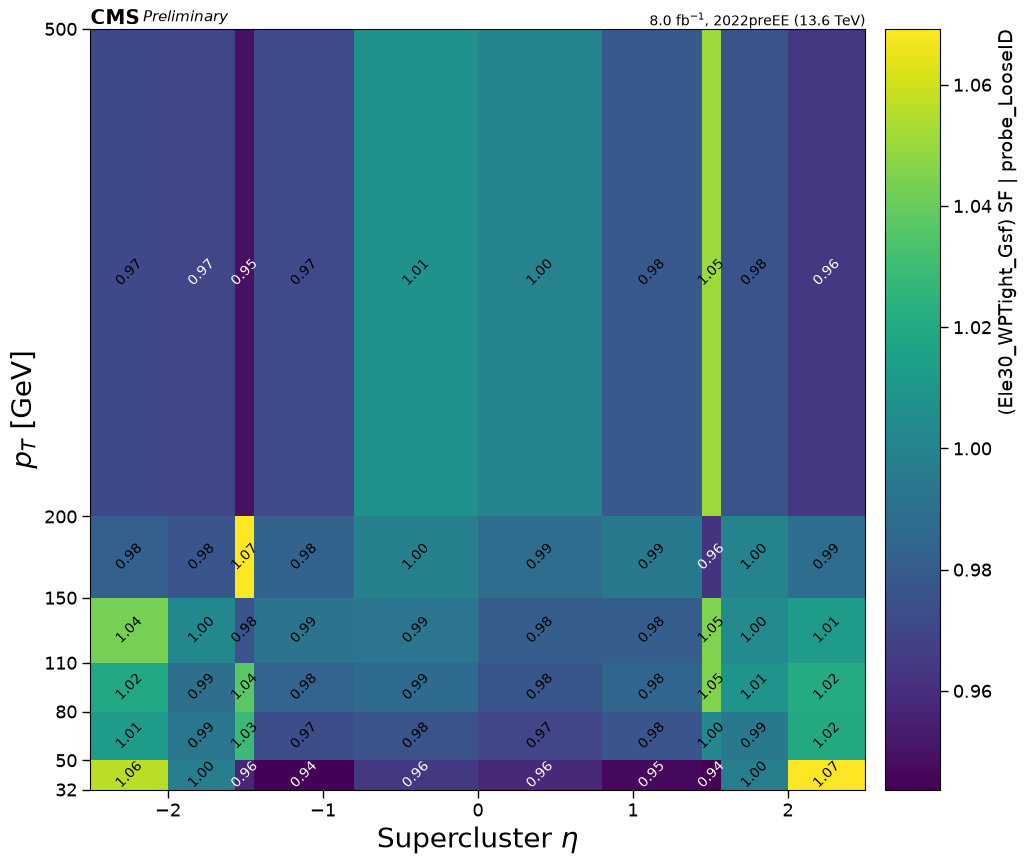

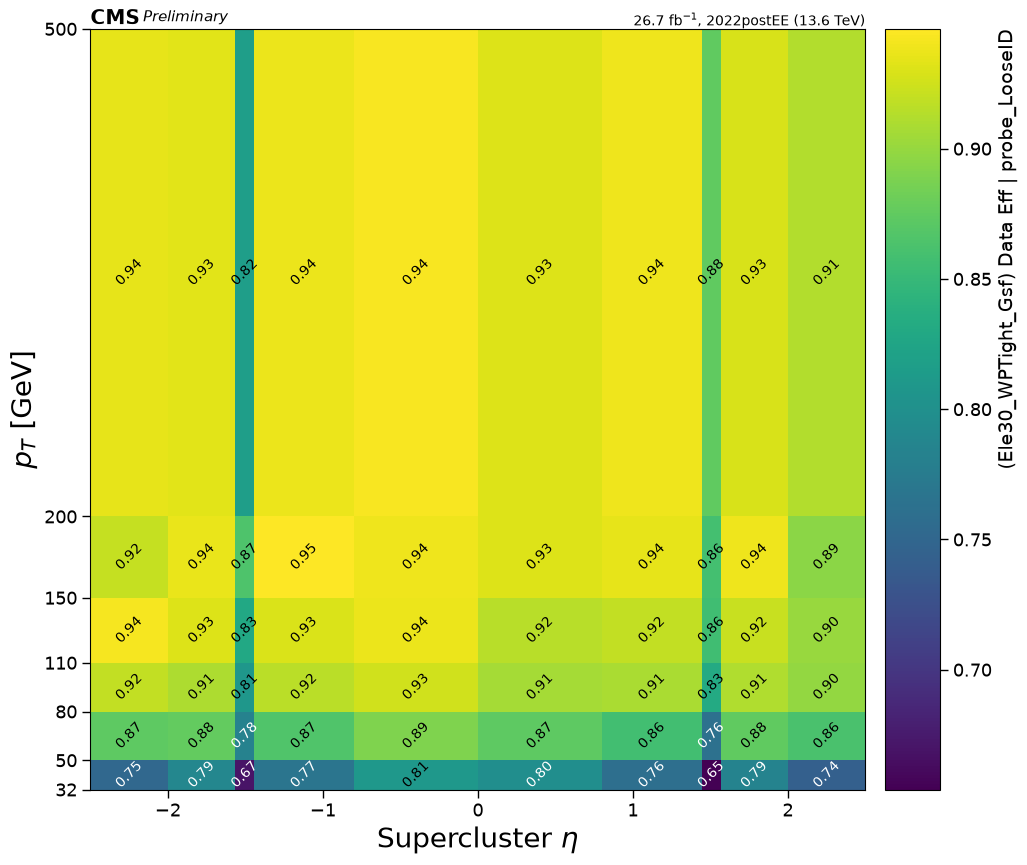

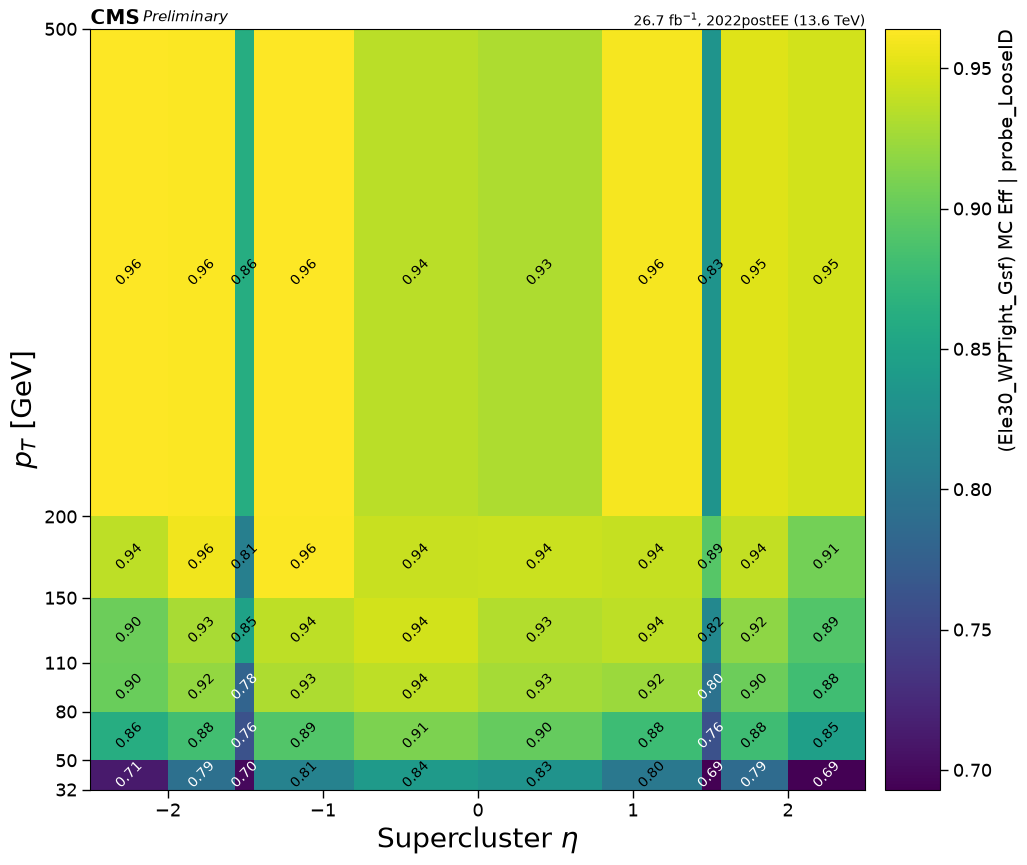

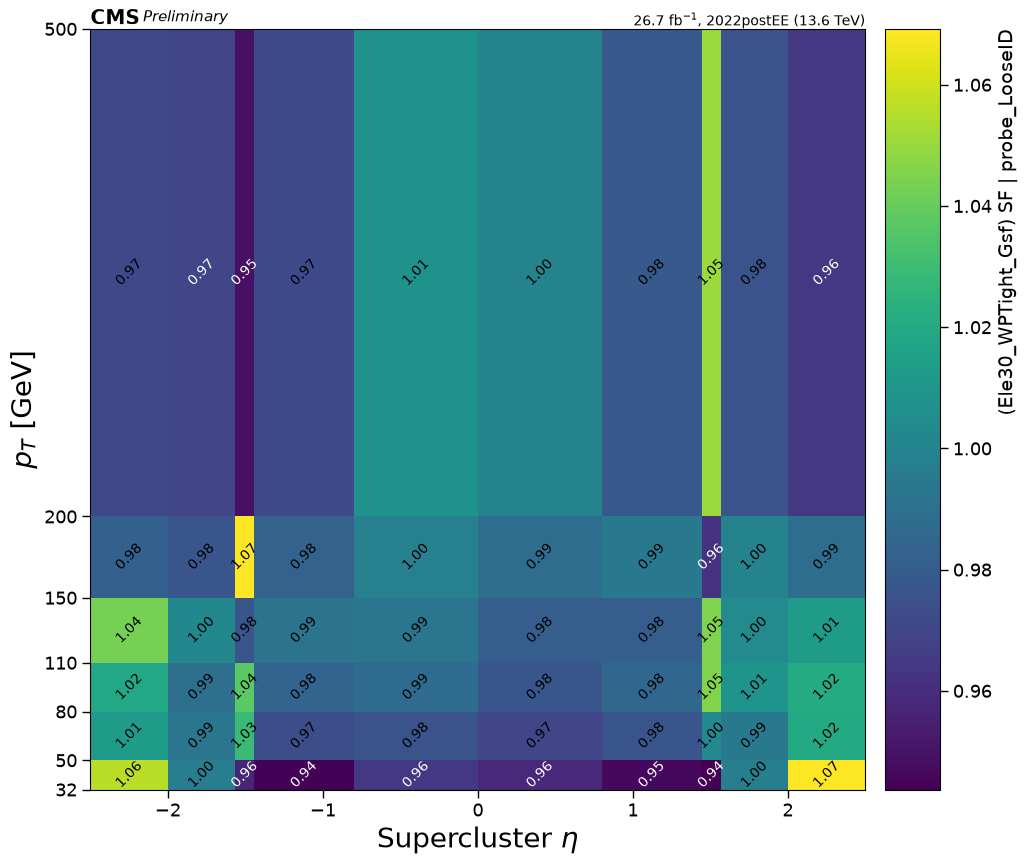

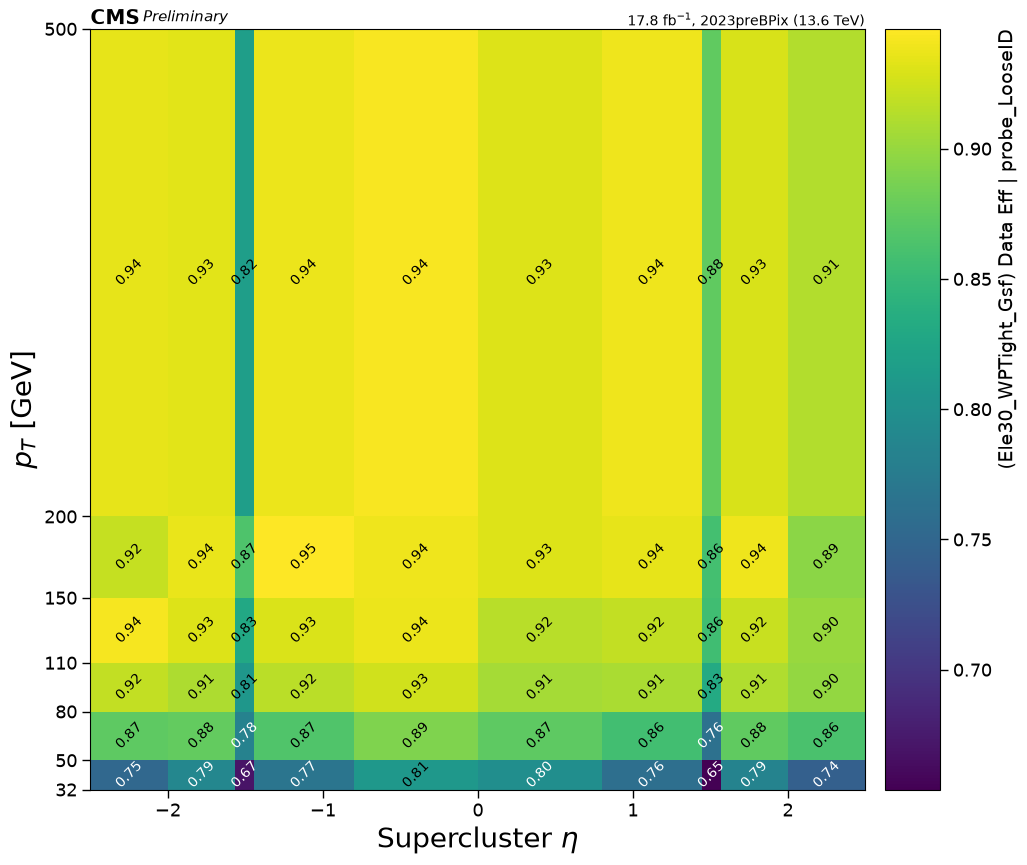

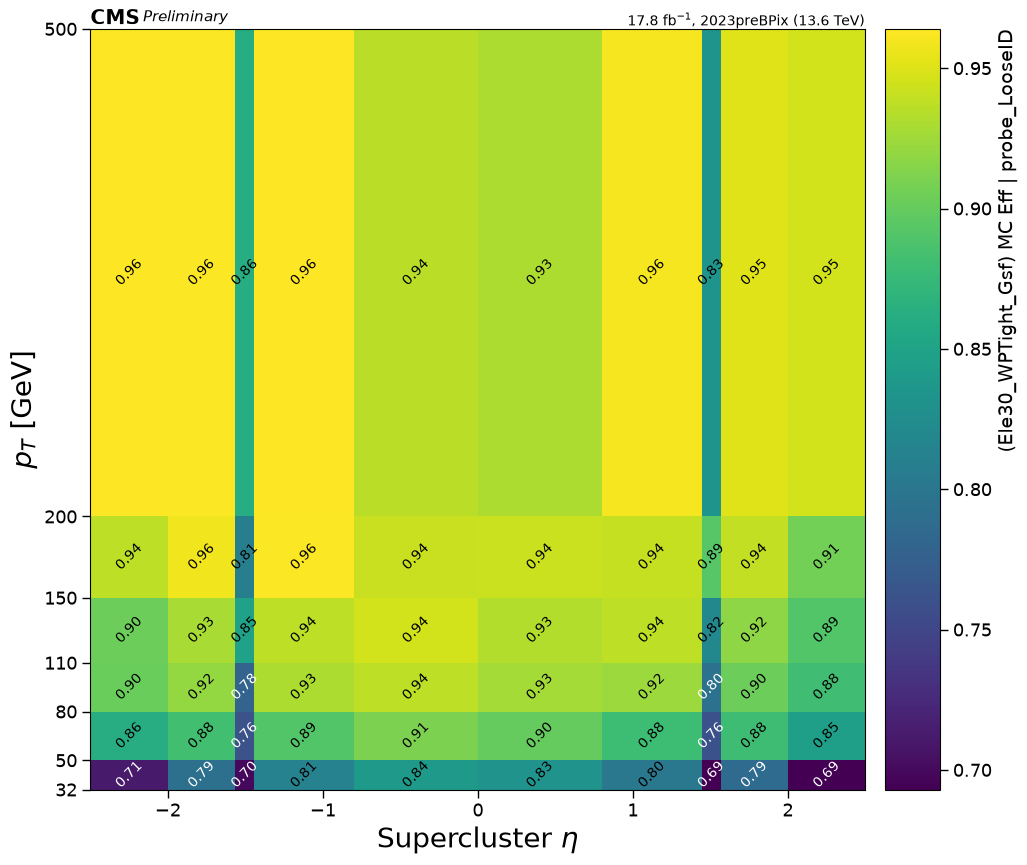

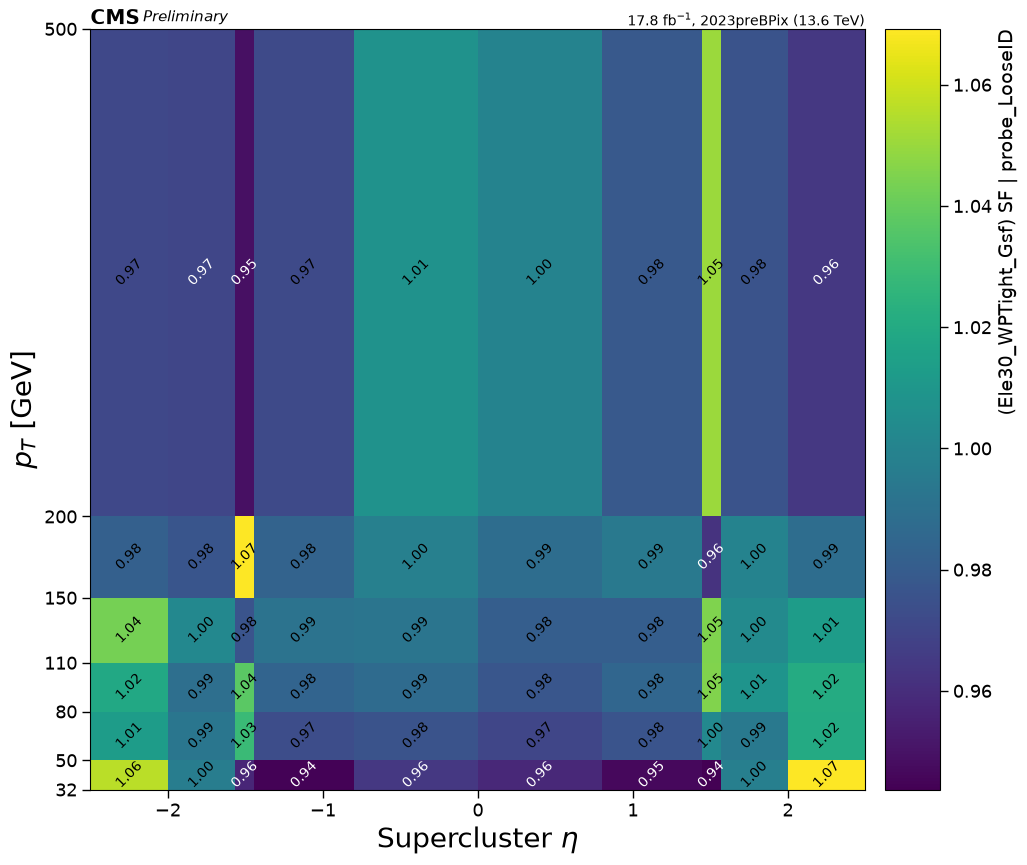

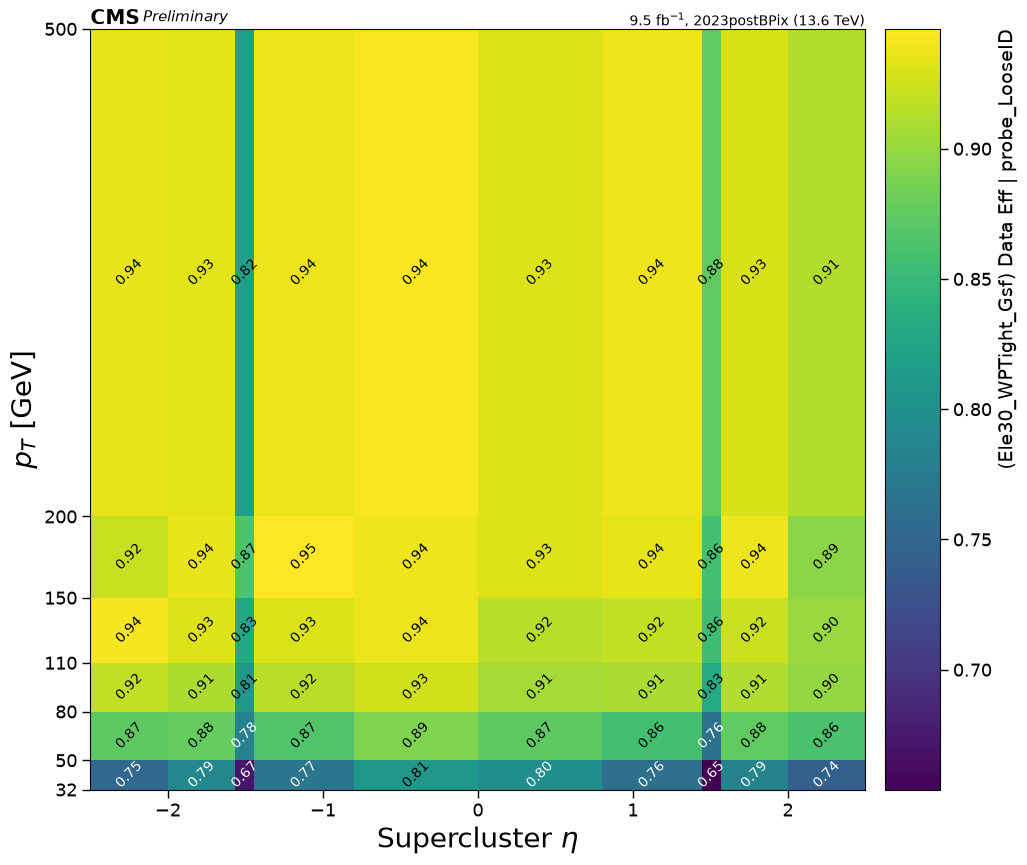

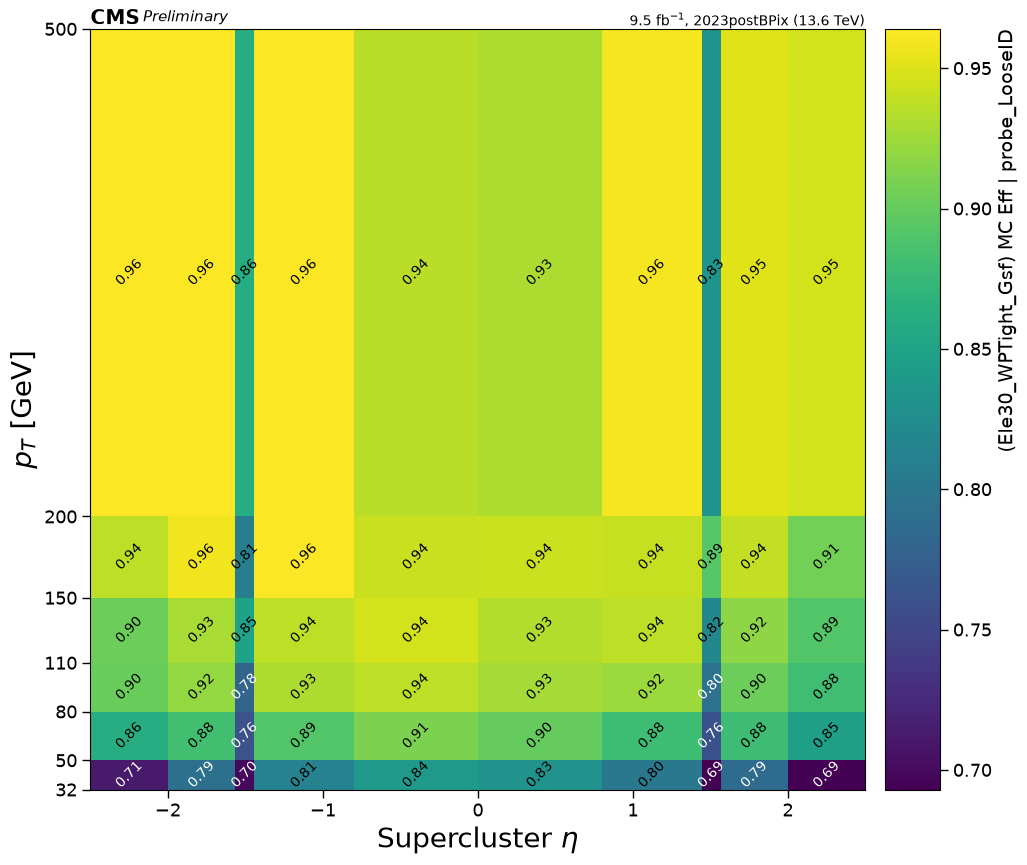

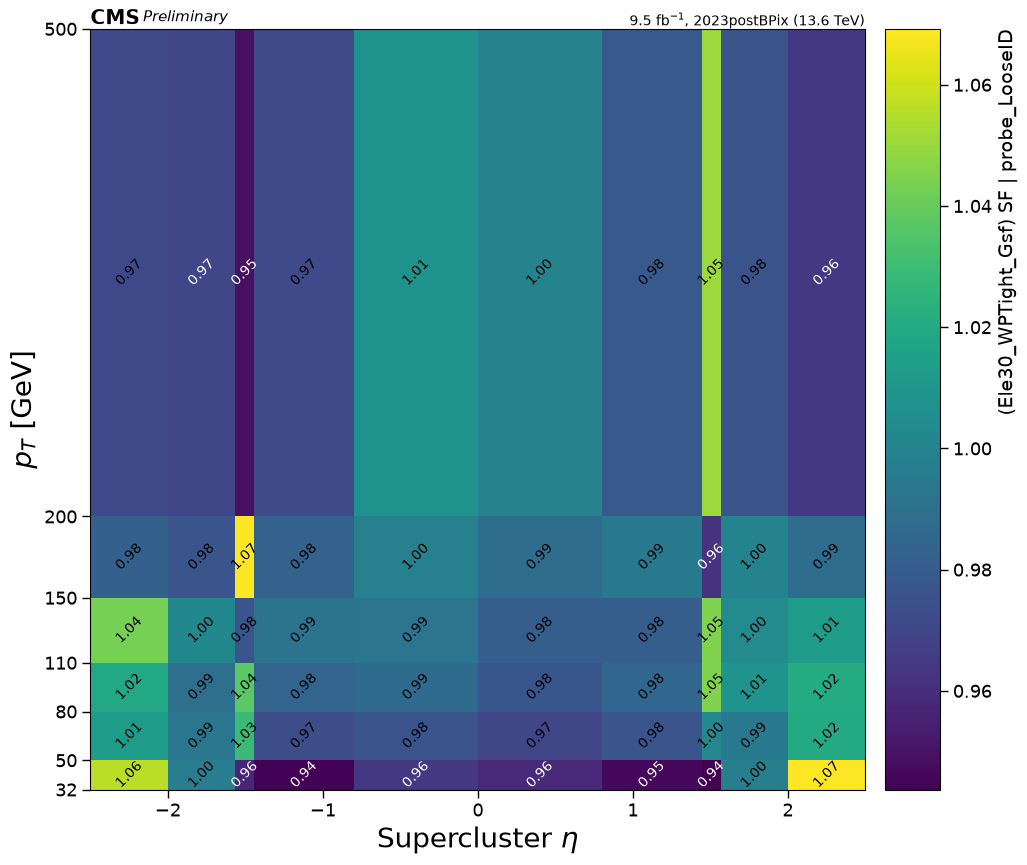

In [21]:
probe = "LooseID"

hlt_paths = {
    "2016preVFP": "Ele27_WPTight_Gsf_OR_Photon175",
    "2016postVFP": "Ele27_WPTight_Gsf_OR_Photon175",
    "2017": "Ele35_WPTight_Gsf_OR_Photon200",
    "2018": "Ele32_WPTight_Gsf",
    "2022preEE": "Ele30_WPTight_Gsf",
    "2022postEE": "Ele30_WPTight_Gsf",
    "2023preBPix": "Ele30_WPTight_Gsf",
    "2023postBPix": "Ele30_WPTight_Gsf",
}

samples = {
    '2022preEE': ['2022','ForRe-recoBCD'],
    '2022postEE': ['2022','ForRe-recoE+PromptFG'],
    '2023preBPix': ['2023','ForPrompt23C'],
    '2023postBPix': ['2023','ForPrompt23D']
}

def add_text(histogram, ax, threshold):
    matrix = histogram.values()
    pt_centers = histogram.axes[0].centers
    eta_centers = histogram.axes[1].centers
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            val = matrix[i, j]
            x = pt_centers[i]
            y = eta_centers[j]
            if val < threshold or np.isnan(val):
                col = "w"
            else:
                col = "k"
            ax.text(
                x,
                y,
                f"{val:.2f}",
                rotation=45,
                ha="center",
                va="center",
                fontsize=10,
                color=col,
            )


def add_info(year, ax):
    with open("../analysis/postprocess/luminosity.yaml", "r") as f:
        lumi = yaml.safe_load(f)
    energy = {"2": "13", "3": "13.6"}
    run_key = "2" if year.startswith("201") else "3"
    lumi_val = float(round(lumi[year] * 1e-3, 1))
    com_val = float(energy[run_key].split()[0])
    hep.cms.label(
        "Preliminary",
        data=True,
        lumi=lumi_val,
        com=com_val,
        year=year,
        ax=ax,
        fontsize=11,
    )
    ax.set_xlabel("Supercluster $\\eta$", fontsize=20)
    ax.set_ylabel("$p_T$ [GeV]", fontsize=20)


def plot_sf(sf_hist, year, threshold=0.97, probe="MVAiso80ID"):
    fig, ax = plt.subplots(figsize=(10, 9), tight_layout=True)
    colormesh = sf_hist.plot2d(ax=ax)
    colormesh[1].set_label(f"({hlt}) SF | {"probe_MVAiso80ID" if year.startswith("201") else "probe_"+probe}", loc="top", fontsize=14)
    add_info(year, ax)
    add_text(sf_hist, ax, threshold)
    fig.savefig(
        f"plots/{year}_{hlt}_SF_MVAiso80ID.pdf" if year.startswith("201")
        else f"plots/{year}_{hlt}_SF_{probe}.pdf"
        )
    fig.savefig(f"plots/{year}_{hlt}_SF.pdf")


def plot_eff(eff_hist, year, is_mc=True, threshold=0.8, probe="MVAiso80ID"):
    kind = "MC" if is_mc else "Data"
    fig, ax = plt.subplots(figsize=(10, 9), tight_layout=True)
    colormesh = eff_hist.plot2d(ax=ax)
    colormesh[1].set_label(f"({hlt}) {kind} Eff | {"probe_MVAiso80ID" if year.startswith("201") else "probe_"+probe}", loc="top", fontsize=14)
    add_info(year, ax)
    add_text(eff_hist, ax, threshold)
    fig.savefig(
        f"plots/{year}_{hlt}_{kind.lower()}Eff_MVAiso80ID.pdf" if year.startswith("201")
        else f"plots/{year}_{hlt}_{kind.lower()}Eff_{probe}.pdf"
        )


for year, hlt in hlt_paths.items():
    if year.startswith("201"):
        tree = uproot.open(f"../analysis/data/egammaEffi_EGM2D_{year}.root")
    else:
        path = f"/eos/cms/store/group/phys_egamma/ScaleFactors/Data{samples[year][0]}/{samples[year][1]}/tnpEleHLT/HLT_SF_Ele30_{probe}/egammaEffi.txt_EGM2D.root"
    sfhist = tree["EGamma_SF2D"].to_hist()
    data_effhist = tree["EGamma_EffData2D"].to_hist()
    mc_effhist = tree["EGamma_EffMC2D"].to_hist()
    plot_eff(data_effhist, year, is_mc=False, probe=probe)
    plot_eff(mc_effhist, year, is_mc=True, probe=probe)
    plot_sf(sfhist, year, probe=probe)

In [22]:
for year, hlt in hlt_paths.items():
    print(year.upper())
    run2=year.startswith("201")
    if run2:
        path = f"../analysis/data/egammaEffi_EGM2D_{year}.root"
    else:
        path = f"/eos/cms/store/group/phys_egamma/ScaleFactors/Data{samples[year][0]}/{samples[year][1]}/tnpEleHLT/HLT_SF_Ele30_{probe}/egammaEffi.txt_EGM2D.root"
    tree = uproot.open(path)
    # save HLT scale factors to correctionlib object
    sfhist = tree['EGamma_SF2D;1'].to_hist()
    sfhist.name = f"HLT_SF_{hlt}_MVAiso80ID" if run2 else f"HLT_SF_{hlt}_{probe}"
    sfhist.label = "out"
    hlt_sf = correctionlib.convert.from_histogram(sfhist)
    hlt_sf.description = f"These are the electron {hlt} scale factors (nominal) for the {"MVAiso80ID" if run2 else probe} WP and {year} dataset. They are dependent on the transverse momenta and supercluster pseudorapidity of the electron."
    hlt_sf.data.flow = "clamp"
    rich.print(hlt_sf)
    cset = correctionlib.schemav2.CorrectionSet(
        schema_version=2,
        description=f"HLT_SF_{hlt}_{"MVAiso80ID" if run2 else probe}",
        corrections=[
            hlt_sf
        ],
    )
    write_sf_in = f"../analysis/data/EGamma_HLT_SF_{year}_{"MVAiso80ID" if run2 else probe}.json.gz"
    with gzip.open(write_sf_in, "wt") as fout:
        fout.write(cset.json(exclude_unset=True))

    # save Data/MC HLT efficiencies to correctionlib object
    for key in ["Data", "MC"]:
        effhist = tree[f'EGamma_Eff{key}2D;1'].to_hist()
        effhist.name = f"HLT_{key}Eff_{hlt}_{"MVAiso80ID" if run2 else probe}"
        effhist.label = "out"
        hlt_eff = correctionlib.convert.from_histogram(effhist)
        hlt_eff.description = f"These are the electron {hlt} efficiencies in {key} (nominal) for the {"MVAiso80ID" if run2 else probe} WP and {year} dataset. They are dependent on the transverse momenta and supercluster pseudorapidity of the electron."
        hlt_eff.data.flow = "clamp"
        rich.print(hlt_eff)
        cset = correctionlib.schemav2.CorrectionSet(
            schema_version=2,
            description=f"HLT_{key}Eff_{hlt}_{"MVAiso80ID" if run2 else probe}",
            corrections=[
                hlt_eff
            ],
        )
        write_eff_in = f"../analysis/data/EGamma_HLT_{key}Eff_{year}_{"MVAiso80ID" if run2 else probe}.json.gz"
        with gzip.open(write_eff_in, "wt") as fout:
            fout.write(cset.json(exclude_unset=True))

2016PREVFP


📈 HLT_SF_Ele27_WPTight_Gsf_OR_Photon175_MVAiso80ID (v0)
These are the electron Ele27_WPTight_Gsf_OR_Photon175 scale factors (nominal) for the MVAiso80ID WP and 2016preVFP 
dataset. They are dependent on the transverse momenta and supercluster pseudorapidity of the electron.
Node counts: MultiBinning: 1
╭──────────── ▶ input ────────────╮ ╭───────────── ▶ input ─────────────╮
│ xaxis (real)                    │ │ yaxis (real)                      │
│ SuperCluster #eta               │ │ p_{T} [GeV]                       │
│ Range: [-2.5, 2.5), overflow ok │ │ Range: [27.0, 500.0), overflow ok │
╰─────────────────────────────────╯ ╰───────────────────────────────────╯
╭─── ◀ output ───╮
│ out (real)     │
│ No description │
╰────────────────╯

/tmp/driosper/ipykernel_2881854/3352510487.py:26: PydanticDeprecatedSince20: The `json` method is deprecated; use `model_dump_json` instead. Deprecated in Pydantic V2.0 to be removed in V3.0. See Pydantic V2 Migration Guide at https://errors.pydantic.dev/2.13/migration/
  fout.write(cset.json(exclude_unset=True))


📈 HLT_DataEff_Ele27_WPTight_Gsf_OR_Photon175_MVAiso80ID (v0)
These are the electron Ele27_WPTight_Gsf_OR_Photon175 efficiencies in Data (nominal) for the MVAiso80ID WP and 
2016preVFP dataset. They are dependent on the transverse momenta and supercluster pseudorapidity of the electron.
Node counts: MultiBinning: 1
╭──────────── ▶ input ────────────╮ ╭───────────── ▶ input ─────────────╮
│ xaxis (real)                    │ │ yaxis (real)                      │
│ SuperCluster #eta               │ │ p_{T} [GeV]                       │
│ Range: [-2.5, 2.5), overflow ok │ │ Range: [27.0, 500.0), overflow ok │
╰─────────────────────────────────╯ ╰───────────────────────────────────╯
╭─── ◀ output ───╮
│ out (real)     │
│ No description │
╰────────────────╯

/tmp/driosper/ipykernel_2881854/3352510487.py:46: PydanticDeprecatedSince20: The `json` method is deprecated; use `model_dump_json` instead. Deprecated in Pydantic V2.0 to be removed in V3.0. See Pydantic V2 Migration Guide at https://errors.pydantic.dev/2.13/migration/
  fout.write(cset.json(exclude_unset=True))


...

📈 HLT_MCEff_Ele30_WPTight_Gsf_LooseID (v0)
These are the electron Ele30_WPTight_Gsf efficiencies in MC (nominal) for the MVAiso80ID WP and 2023preBPix 
dataset. They are dependent on the transverse momenta and supercluster pseudorapidity of the electron.
Node counts: MultiBinning: 1
╭──────────── ▶ input ────────────╮ ╭───────────── ▶ input ─────────────╮
│ xaxis (real)                    │ │ yaxis (real)                      │
│ SuperCluster #eta               │ │ p_{T} [GeV]                       │
│ Range: [-2.5, 2.5), overflow ok │ │ Range: [25.0, 500.0), overflow ok │
╰─────────────────────────────────╯ ╰───────────────────────────────────╯
╭─── ◀ output ───╮
│ out (real)     │
│ No description │
╰────────────────╯

2023POSTBPIX


📈 HLT_SF_Ele30_WPTight_Gsf_LooseID (v0)
These are the electron Ele30_WPTight_Gsf scale factors (nominal) for the LooseID WP and 2023postBPix dataset. They 
are dependent on the transverse momenta and supercluster pseudorapidity of the electron.
Node counts: MultiBinning: 1
╭──────────── ▶ input ────────────╮ ╭───────────── ▶ input ─────────────╮
│ xaxis (real)                    │ │ yaxis (real)                      │
│ SuperCluster #eta               │ │ p_{T} [GeV]                       │
│ Range: [-2.5, 2.5), overflow ok │ │ Range: [25.0, 500.0), overflow ok │
╰─────────────────────────────────╯ ╰───────────────────────────────────╯
╭─── ◀ output ───╮
│ out (real)     │
│ No description │
╰────────────────╯

📈 HLT_DataEff_Ele30_WPTight_Gsf_LooseID (v0)
These are the electron Ele30_WPTight_Gsf efficiencies in Data (nominal) for the MVAiso80ID WP and 2023postBPix 
dataset. They are dependent on the transverse momenta and supercluster pseudorapidity of the electron.
Node counts: MultiBinning: 1
╭──────────── ▶ input ────────────╮ ╭───────────── ▶ input ─────────────╮
│ xaxis (real)                    │ │ yaxis (real)                      │
│ SuperCluster #eta               │ │ p_{T} [GeV]                       │
│ Range: [-2.5, 2.5), overflow ok │ │ Range: [25.0, 500.0), overflow ok │
╰─────────────────────────────────╯ ╰───────────────────────────────────╯
╭─── ◀ output ───╮
│ out (real)     │
│ No description │
╰────────────────╯

📈 HLT_MCEff_Ele30_WPTight_Gsf_LooseID (v0)
These are the electron Ele30_WPTight_Gsf efficiencies in MC (nominal) for the MVAiso80ID WP and 2023postBPix 
dataset. They are dependent on the transverse momenta and supercluster pseudorapidity of the electron.
Node counts: MultiBinning: 1
╭──────────── ▶ input ────────────╮ ╭───────────── ▶ input ─────────────╮
│ xaxis (real)                    │ │ yaxis (real)                      │
│ SuperCluster #eta               │ │ p_{T} [GeV]                       │
│ Range: [-2.5, 2.5), overflow ok │ │ Range: [25.0, 500.0), overflow ok │
╰─────────────────────────────────╯ ╰───────────────────────────────────╯
╭─── ◀ output ───╮
│ out (real)     │
│ No description │
╰────────────────╯